In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor, Lambda, Compose
import matplotlib.pyplot as plt

# 0. setup a device agnostic

In [2]:
# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


# 1.data preparing and loading
I want to stress that "data" in machine learning can be almost anything you can imagine. A table of numbers (like a big Excel spreadsheet), images of any kind, videos (YouTube has lots of data!), audio files like songs or podcasts, protein structures, text and more.

In [3]:
# create wights and bias
weight = 0.7
bias = 0.3

# creata  a range of data
start = 0
end = 1
step = 0.02

x  =torch.arange(start , end , step).unsqueeze(dim=1)
y = weight * x + bias


In [4]:
x , y

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800],
         [0.2000],
         [0.2200],
         [0.2400],
         [0.2600],
         [0.2800],
         [0.3000],
         [0.3200],
         [0.3400],
         [0.3600],
         [0.3800],
         [0.4000],
         [0.4200],
         [0.4400],
         [0.4600],
         [0.4800],
         [0.5000],
         [0.5200],
         [0.5400],
         [0.5600],
         [0.5800],
         [0.6000],
         [0.6200],
         [0.6400],
         [0.6600],
         [0.6800],
         [0.7000],
         [0.7200],
         [0.7400],
         [0.7600],
         [0.7800],
         [0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.3000],
         [0.3140],
         [

In [5]:
# split the data
train_split = int(0.8 * len(x))
x_train , y_train = x[:train_split] , y[:train_split]
x_test , y_test = x[train_split:] , y[train_split:]

In [6]:
def plot_predictions(train_data=x_train,
                     train_labels=y_train,
                     test_data=x_test,
                     test_labels=y_test,
                     predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10, 7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14});

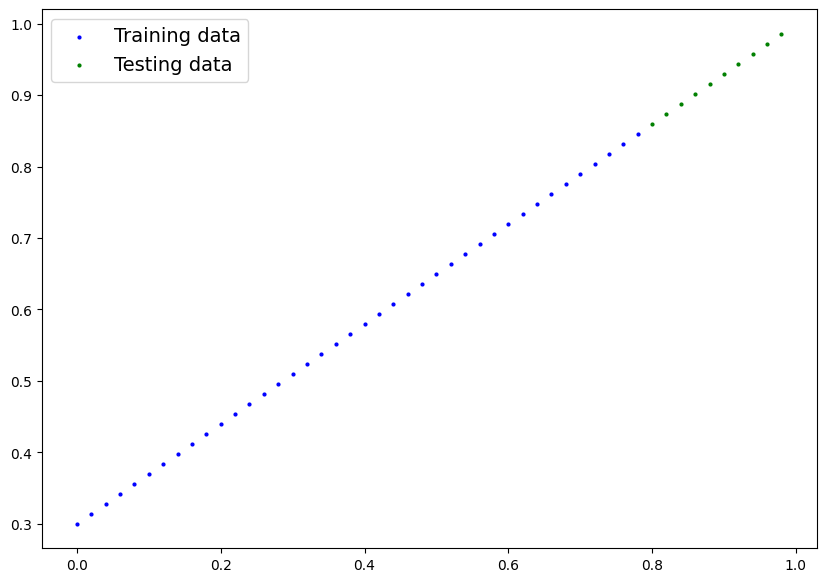

In [7]:
plot_predictions();

#2 Building a PyTorch linear model

In [8]:
class linearregerssion(nn.Module):
    def __init__(self):
      super().__init__()

      self.weights = nn.Parameter(torch.randn(1, requires_grad=True , dtype=torch.float))
      self.bias = nn.Parameter(torch.randn(1, requires_grad=True , dtype=torch.float))

    # forward methode
    def forward(self , x : torch.Tensor) -> torch.Tensor:
      return self.weights * x + self.bias

In [9]:
# set the manual seed to 42
torch.manual_seed(42)

model_0 = linearregerssion()

list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [10]:
model_0.weights

Parameter containing:
tensor([0.3367], requires_grad=True)

In [11]:
model_0.bias

Parameter containing:
tensor([0.1288], requires_grad=True)

In [12]:
# state the names of the parameters in dictionary
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [13]:
# making predcitonn with model
with torch.inference_mode():
  y_preds = model_0(x_test)

In [14]:
y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

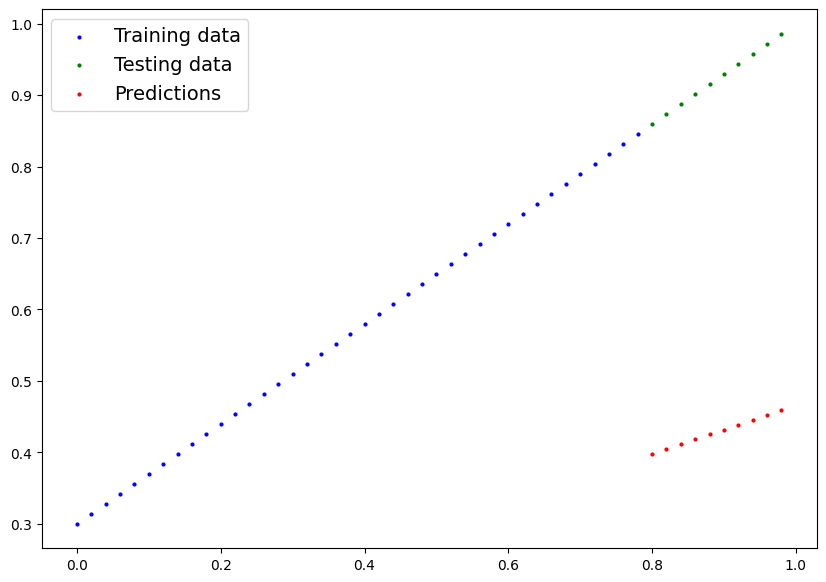

In [15]:
# predictions scater plot
plot_predictions(predictions=y_preds);

#3. train the model
create the loss function and optimizer


In [16]:
# create the loss function
loss_fn = nn.L1Loss() # MAE loss is same as L1Loss
# create the optimzer (stocastic gradiant descent)
optimizer = torch.optim.SGD(params=model_0.parameters(), # parameters of target model to optimize
                            lr=0.01)


create the training loop
1. forwad pass
2. calculate loss
3. zero gradiant
4. perfom backprogation on the loss
5. Update the optimizer (gradient descent)

In [18]:
# set the manual seed
torch.manual_seed(42)

# set the number of epochs
epochs= 100

# Create empty loss lists to track values
train_loss_values = []
test_loss_values = []
epoch_count = []


for epoch in range(epochs):
  ### Training
  model_0.train()

  #1. forward path
  y_pred = model_0(x_train)

  #2. calculate the loss
  loss = loss_fn(y_pred , y_train)
  train_loss_values.append(loss)

  # zero grad to optimizer
  optimizer.zero_grad()

  # loss backward
  loss.backward()

  # optimizer step
  optimizer.step()

  ### Testing
  model_0.eval()
  with torch.inference_mode():
    #1. forward path
    test_pred = model_0(x_test)

    #2. calculate the loss
    test_loss = loss_fn(test_pred , y_test)
    test_loss_values.append(test_loss)

  if epoch % 10 == 0:
    epoch_count.append(epoch)
    train_loss_values.append(loss.detach().numpy())
    test_loss_values.append(test_loss.detach().numpy())
    print(f"Epoch: {epoch} | MAE Train Loss: {loss} | MAE Test Loss: {test_loss} ")

Epoch: 0 | MAE Train Loss: 0.024458957836031914 | MAE Test Loss: 0.05646304413676262 
Epoch: 10 | MAE Train Loss: 0.021020207554101944 | MAE Test Loss: 0.04819049686193466 
Epoch: 20 | MAE Train Loss: 0.01758546568453312 | MAE Test Loss: 0.04060482233762741 
Epoch: 30 | MAE Train Loss: 0.014155393466353416 | MAE Test Loss: 0.03233227878808975 
Epoch: 40 | MAE Train Loss: 0.010716589167714119 | MAE Test Loss: 0.024059748277068138 
Epoch: 50 | MAE Train Loss: 0.0072835334576666355 | MAE Test Loss: 0.016474086791276932 
Epoch: 60 | MAE Train Loss: 0.0038517764769494534 | MAE Test Loss: 0.008201557211577892 
Epoch: 70 | MAE Train Loss: 0.008932482451200485 | MAE Test Loss: 0.005023092031478882 
Epoch: 80 | MAE Train Loss: 0.008932482451200485 | MAE Test Loss: 0.005023092031478882 
Epoch: 90 | MAE Train Loss: 0.008932482451200485 | MAE Test Loss: 0.005023092031478882 


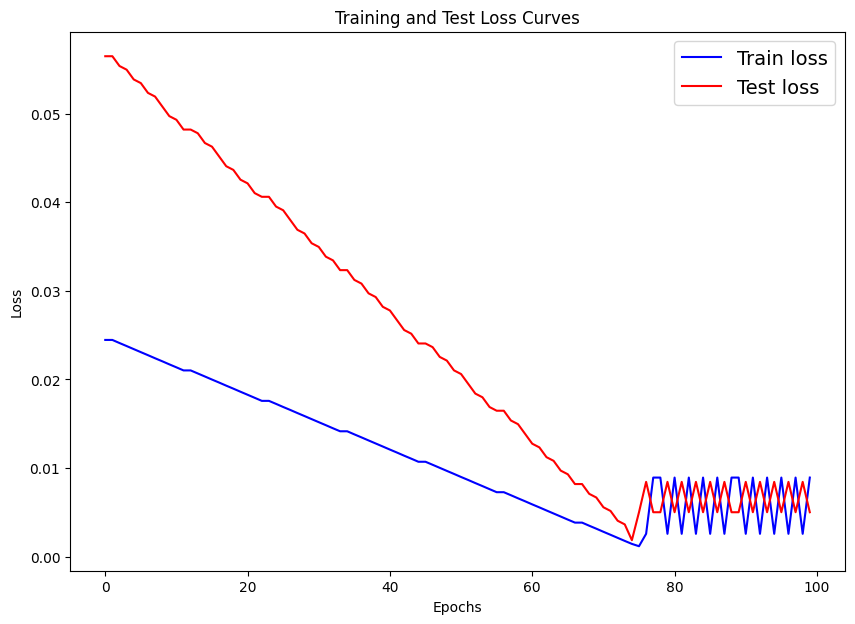

In [19]:
# Plot the loss curves
import numpy as np

# Filter out only PyTorch tensors and convert them to numpy/float for plotting
clean_train_loss = [t.detach().item() if isinstance(t, torch.Tensor) else float(t) for t in train_loss_values]
clean_test_loss = [t.detach().item() if isinstance(t, torch.Tensor) else float(t) for t in test_loss_values]

# Adjust to plot only the 100 training epochs (ignoring the extra appended evaluation steps)
plt.figure(figsize=(10, 7))
plt.plot(clean_train_loss[:epochs], label="Train loss", color="blue")
plt.plot(clean_test_loss[:epochs], label="Test loss", color="red")
plt.title("Training and Test Loss Curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend(prop={"size": 14});

#4. making predictions


In [21]:
# 1 set the model in evaluation mode
model_0.eval()

# 2 turn on inference mode
with torch.inference_mode():
  y_preds = model_0(x_test)

y_preds

tensor([[0.8685],
        [0.8825],
        [0.8965],
        [0.9105],
        [0.9245],
        [0.9384],
        [0.9524],
        [0.9664],
        [0.9804],
        [0.9944]])

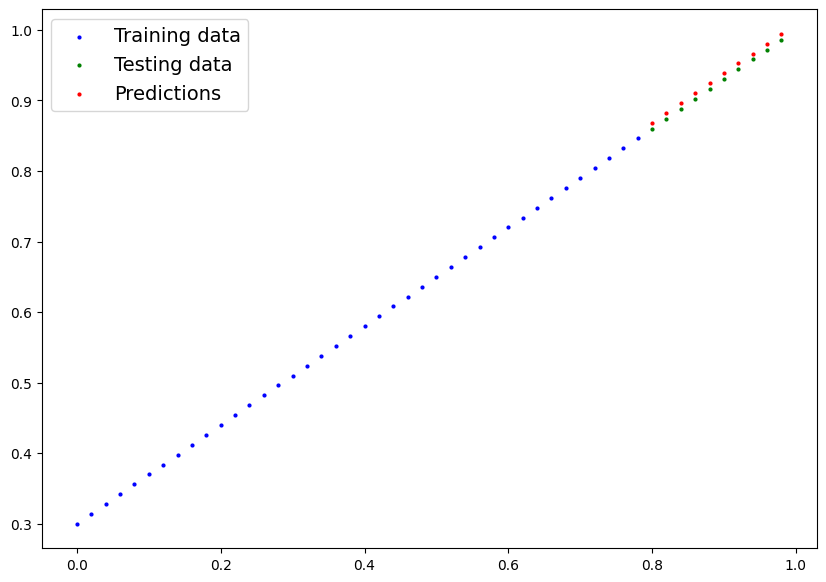

In [22]:
plot_predictions(predictions=y_preds)

# 5. saving and loading pytorch model


In [23]:
from pathlib import Path

# 1. Create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path
MODEL_NAME = "01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(), f=MODEL_SAVE_PATH)

# 4. Instantiate a new instance of our model class
loaded_model_0 = linearregerssion()

# 5. Load the saved state_dict into the new instance
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

# Put loaded model in evaluation mode to verify
loaded_model_0.eval()
with torch.inference_mode():
    loaded_preds = loaded_model_0(x_test)

print(f"Original model predictions match loaded model predictions: {torch.allclose(y_preds, loaded_preds)}")

Saving model to: models/01_pytorch_workflow_model_0.pth
Original model predictions match loaded model predictions: True
